# Week 3 — Forward & Backward Selection, Principal Component Regression (PCR), and Partial Least Squares Regression (PLSR)

**Project:** Predicting Loan Repayment Risk Using LendingClub Data
**Target:** `int_rate` (%), same as Weeks 1–2, on the same train/test split built in Week 1.

Week 2 kept every variable and shrank coefficients. This notebook uses three other ways to reduce model complexity:

* **Forward / backward stepwise selection** keeps a subset of the original variables, so it stays interpretable.
* **PCR** replaces the predictors with their first *M* principal components. The components are chosen **without looking at the target** (unsupervised), and the regression then uses them.
* **PLSR** also builds *M* components, but chooses directions that have high **covariance with the target** (supervised), so it usually needs fewer components than PCR.

In every case the number of variables or components is chosen by **5-fold cross-validation on the training set**, and the selection is redone inside each fold so the procedure does not leak information. The test set is used only at the end.

## 0. Setup

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
import warnings

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)  # spurious numpy 2.x + macOS Accelerate warning; results unaffected
sns.set_theme(style="whitegrid", font="serif")
pd.set_option("display.float_format", "{:,.4f}".format)
print("scikit-learn", sklearn.__version__)

DATA = Path("data/lc_model_sample.parquet")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
CV = KFold(5, shuffle=True, random_state=RANDOM_STATE)
SELECTION_N = 40_000   # training-row subsample for the stepwise search (hundreds of model fits)

NUM = ["loan_amnt", "log_annual_inc", "dti", "fico", "inq_last_6mths", "delinq_2yrs", "open_acc",
       "total_acc", "revol_util", "log_revol_bal", "pub_rec", "mort_acc", "pub_rec_bankruptcies",
       "credit_hist_years", "emp_length_yrs", "ever_delinq"]
CAT = ["term", "home_ownership", "verification_status", "purpose", "application_type", "initial_list_status"]
TARGET = "int_rate"

df = pd.read_parquet(DATA)
df[NUM] = df[NUM].astype(float)
for c in CAT:
    df[c] = df[c].astype("string").fillna("Missing").astype(object)
CAT = [c for c in CAT if df.loc[df.split == "train", c].nunique() > 1]
train, test = df[df.split == "train"], df[df.split == "test"]
X_tr, y_tr = train[NUM + CAT], train[TARGET].astype(float)
X_te, y_te = test[NUM + CAT], test[TARGET].astype(float)
print(f"train {X_tr.shape}, test {X_te.shape}")

def make_pre(num, cat):
    parts = []
    if num:
        parts.append(("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num))
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False), cat))
    return ColumnTransformer(parts)

def ols(variables):
    return Pipeline([("pre", make_pre([v for v in variables if v in NUM], [v for v in variables if v in CAT])),
                     ("reg", LinearRegression())])

def cv_rmse(model, X, y):
    s = -cross_val_score(model, X, y, cv=CV, scoring="neg_root_mean_squared_error")
    return s.mean(), s.std() / np.sqrt(len(s))

scikit-learn 1.6.1


train (140000, 22), test (60000, 22)


## 1. Forward and backward stepwise selection

Selection works on **variables**, not dummy columns. A categorical variable such as `purpose` enters or leaves as one block, which keeps the result interpretable. At each step the variable whose addition (forward) or removal (backward) gives the lowest 5-fold CV RMSE is chosen. scikit-learn's `SequentialFeatureSelector` does the same search but treats each dummy as a separate feature and returns only the final subset. Writing the loop by hand gives the whole path for plotting.

Model size is chosen with the **one-standard-error rule**: the smallest model whose CV RMSE is within one SE of the best.

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
sel_idx = rng.choice(len(X_tr), size=min(SELECTION_N, len(X_tr)), replace=False)
Xs, ys = X_tr.iloc[sel_idx], y_tr.iloc[sel_idx]
ALL = NUM + CAT

def forward_selection(X, y):
    chosen, path = [], []
    remaining = list(ALL)
    while remaining:
        scores = {v: cv_rmse(ols(chosen + [v]), X, y) for v in remaining}
        best = min(scores, key=lambda v: scores[v][0])
        chosen.append(best); remaining.remove(best)
        path.append({"k": len(chosen), "added": best, "cv_rmse": scores[best][0], "se": scores[best][1]})
    return pd.DataFrame(path)

def backward_selection(X, y):
    current = list(ALL)
    m, se = cv_rmse(ols(current), X, y)
    path = [{"k": len(current), "removed": None, "cv_rmse": m, "se": se, "vars": list(current)}]
    while len(current) > 1:
        scores = {v: cv_rmse(ols([u for u in current if u != v]), X, y) for v in current}
        worst = min(scores, key=lambda v: scores[v][0])
        current.remove(worst)
        path.append({"k": len(current), "removed": worst, "cv_rmse": scores[worst][0], "se": scores[worst][1], "vars": list(current)})
    return pd.DataFrame(path)

t0 = time.time(); fwd = forward_selection(Xs, ys); print(f"forward: {time.time()-t0:.0f}s")
t0 = time.time(); bwd = backward_selection(Xs, ys); print(f"backward: {time.time()-t0:.0f}s")
fwd

forward: 109s


backward: 186s


,k,added,cv_rmse,se
0,1,fico,3.6490,0.0115
1,2,term,3.3180,0.0125
2,3,purpose,3.1682,0.0122
3,4,inq_last_6mths,3.0771,0.0138
4,5,log_annual_inc,3.0319,0.0148
5,6,loan_amnt,2.9859,0.0148
6,7,revol_util,2.9501,0.0158
7,8,initial_list_status,2.9212,0.0145
8,9,log_revol_bal,2.8953,0.0144
9,10,verification_status,2.8714,0.0147


Forward (1-SE): 13 variables -> ['fico', 'term', 'purpose', 'inq_last_6mths', 'log_annual_inc', 'loan_amnt', 'revol_util', 'initial_list_status', 'log_revol_bal', 'verification_status', 'dti', 'credit_hist_years', 'total_acc']
Backward (1-SE): 13 variables -> ['loan_amnt', 'log_annual_inc', 'dti', 'fico', 'inq_last_6mths', 'open_acc', 'total_acc', 'revol_util', 'log_revol_bal', 'term', 'verification_status', 'purpose', 'initial_list_status']
Same set? False


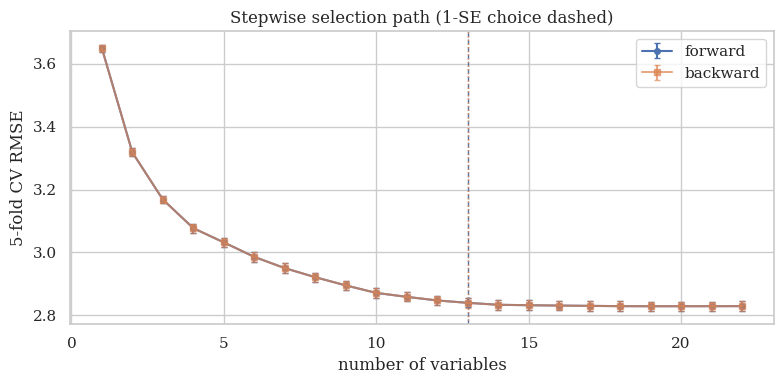

In [3]:
def one_se_k(path):
    best = path.loc[path["cv_rmse"].idxmin()]
    return int(path.loc[path["cv_rmse"] <= best["cv_rmse"] + best["se"], "k"].min())

k_fwd, k_bwd = one_se_k(fwd), one_se_k(bwd)
vars_fwd = list(fwd.sort_values("k")["added"].iloc[:k_fwd])
vars_bwd = bwd.loc[bwd["k"] == k_bwd, "vars"].iloc[0]
print(f"Forward (1-SE): {k_fwd} variables -> {vars_fwd}")
print(f"Backward (1-SE): {k_bwd} variables -> {vars_bwd}")
print("Same set?", set(vars_fwd) == set(vars_bwd))

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(fwd["k"], fwd["cv_rmse"], yerr=fwd["se"], marker="o", ms=4, capsize=2, label="forward")
ax.errorbar(bwd["k"], bwd["cv_rmse"], yerr=bwd["se"], marker="s", ms=4, capsize=2, label="backward", alpha=0.7)
ax.axvline(k_fwd, ls="--", c="C0", lw=1); ax.axvline(k_bwd, ls=":", c="C1", lw=1)
ax.set(xlabel="number of variables", ylabel="5-fold CV RMSE", title="Stepwise selection path (1-SE choice dashed)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG_DIR / "week3_stepwise_path.png", dpi=200); plt.show()

## 2. Principal component regression (PCR)

All predictors are standardized and one-hot encoded, then PCA → linear regression. Standardizing matters: without it, the components would be dominated by large-scale variables such as loan amount.

In [4]:
pre_full = make_pre(NUM, CAT).fit(X_tr)
p = len(pre_full.get_feature_names_out())
print("Columns after encoding:", p)

pca = PCA().fit(pre_full.transform(X_tr))
cumvar = np.cumsum(pca.explained_variance_ratio_)

M_grid = list(range(1, p + 1))
pcr_scores = []
for m in M_grid:
    pcr = Pipeline([("pre", make_pre(NUM, CAT)), ("pca", PCA(n_components=m)), ("reg", LinearRegression())])
    pcr_scores.append(cv_rmse(pcr, X_tr, y_tr))
pcr_cv = pd.DataFrame(pcr_scores, columns=["cv_rmse", "se"], index=M_grid)

Columns after encoding: 40


## 3. Partial least squares regression (PLSR)

PCR chosen components (1-SE): 29  (explains 99.9% of predictor variance)
PLSR chosen components (1-SE): 13


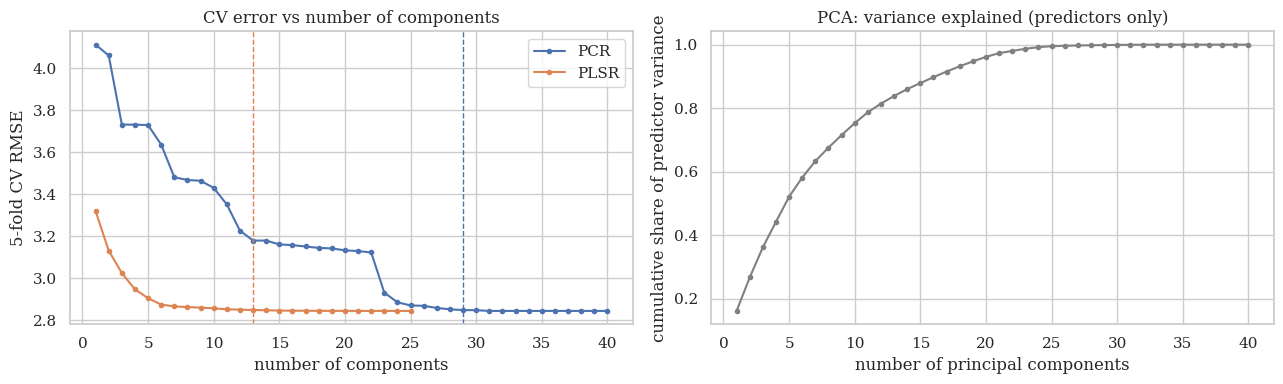

In [5]:
pls_grid = list(range(1, min(25, p) + 1))
pls_scores = []
for m in pls_grid:
    pls = Pipeline([("pre", make_pre(NUM, CAT)), ("pls", PLSRegression(n_components=m, scale=False))])
    pls_scores.append(cv_rmse(pls, X_tr, y_tr))
pls_cv = pd.DataFrame(pls_scores, columns=["cv_rmse", "se"], index=pls_grid)

def one_se_m(cvdf):
    b = cvdf["cv_rmse"].idxmin()
    return int(cvdf.index[cvdf["cv_rmse"] <= cvdf.loc[b, "cv_rmse"] + cvdf.loc[b, "se"]].min())
m_pcr, m_pls = one_se_m(pcr_cv), one_se_m(pls_cv)
print(f"PCR chosen components (1-SE): {m_pcr}  (explains {cumvar[m_pcr-1]:.1%} of predictor variance)")
print(f"PLSR chosen components (1-SE): {m_pls}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(pcr_cv.index, pcr_cv["cv_rmse"], marker=".", label="PCR")
axes[0].plot(pls_cv.index, pls_cv["cv_rmse"], marker=".", label="PLSR")
axes[0].axvline(m_pcr, ls="--", c="C0", lw=1); axes[0].axvline(m_pls, ls="--", c="C1", lw=1)
axes[0].set(xlabel="number of components", ylabel="5-fold CV RMSE", title="CV error vs number of components"); axes[0].legend()
axes[1].plot(range(1, p + 1), cumvar, marker=".", color="grey")
axes[1].set(xlabel="number of principal components", ylabel="cumulative share of predictor variance",
            title="PCA: variance explained (predictors only)")
plt.tight_layout(); plt.savefig(FIG_DIR / "week3_pcr_plsr.png", dpi=200); plt.show()

**Why PLSR usually needs fewer components:** the first PCA directions capture the most *predictor* variance, which need not relate to interest rate. PLS directions are chosen for covariance with the rate, so the first few already carry most of the signal.

In [6]:
# What does the first PLS component load on?
pls1 = Pipeline([("pre", make_pre(NUM, CAT)), ("pls", PLSRegression(n_components=m_pls, scale=False))]).fit(X_tr, y_tr)
load = pd.Series(pls1["pls"].x_weights_[:, 0], index=[n.split("__")[-1] for n in pls1["pre"].get_feature_names_out()])
load.reindex(load.abs().sort_values(ascending=False).index).head(10).to_frame("PLS component 1 weight")

,PLS component 1 weight
fico,0.6285
revol_util,-0.3956
inq_last_6mths,-0.3511
log_annual_inc,0.2209
credit_hist_years,0.1959
dti,-0.1812
verification_status_Verified,-0.1495
initial_list_status_f,-0.1411
initial_list_status_w,0.1411
term_36,0.1325


## 4. Final comparison on the held-out test set

In [7]:
final = {
    "OLS, all variables": ols(ALL),
    f"Forward selection ({k_fwd} vars)": ols(vars_fwd),
    f"Backward selection ({k_bwd} vars)": ols(vars_bwd),
    f"PCR ({m_pcr} comps)": Pipeline([("pre", make_pre(NUM, CAT)), ("pca", PCA(n_components=m_pcr)), ("reg", LinearRegression())]),
    f"PLSR ({m_pls} comps)": Pipeline([("pre", make_pre(NUM, CAT)), ("pls", PLSRegression(n_components=m_pls, scale=False))]),
}
rows = []
for name, model in final.items():
    cv_m, _ = cv_rmse(model, X_tr, y_tr)
    model.fit(X_tr, y_tr)
    pred_tr, pred_te = np.ravel(model.predict(X_tr)), np.ravel(model.predict(X_te))
    rows.append({"model": name, "train_RMSE": np.sqrt(mean_squared_error(y_tr, pred_tr)), "CV_RMSE": cv_m,
                 "test_RMSE": np.sqrt(mean_squared_error(y_te, pred_te)), "test_R2": r2_score(y_te, pred_te)})
week3_results = pd.DataFrame(rows).set_index("model")
week3_results.to_csv(RES_DIR / "week3_regression_results.csv")
week3_results

,train_RMSE,CV_RMSE,test_RMSE,test_R2
model,,,,
"OLS, all variables",2.8429,2.8441,2.8572,0.5252
Forward selection (13 vars),2.8534,2.8542,2.8689,0.5213
Backward selection (13 vars),2.8535,2.8542,2.8691,0.5213
PCR (29 comps),2.8472,2.8481,2.8609,0.5240
PLSR (13 comps),2.8477,2.8485,2.8620,0.5237


## 5. Conclusions

**Stepwise selection.** With the one-standard-error rule, forward and backward selection each keep 13 of 22 variables and agree on 12. Forward adds `credit_hist_years` and backward keeps `open_acc` instead. FICO, term, purpose, recent inquiries, and income enter first, so these are the strongest single drivers of the rate. The 13-variable models lose only 0.012 in test RMSE (2.869 vs. 2.857 for all variables).

**PCR vs. PLSR.** PCR needs 29 components (99.9% of predictor variance) while PLSR needs 13. PLS directions are chosen for their covariance with the rate, whereas PCR's are chosen only to explain the predictors. Neither beats OLS on test RMSE (PCR 2.861, PLSR 2.862, OLS 2.857). With 140,000 rows and only about 40 encoded columns, OLS is not variance-limited, so dimension reduction trades a little accuracy for simplicity.

**Interpretability trade-off.** Stepwise models keep named variables a lender can explain. PCR and PLSR coefficients belong to components: the first PLS component is mostly FICO (weight 0.63) against revolving utilization (−0.40) and inquiries (−0.35), which is readable but less direct.

**Comparison with Week 2.** The two methods disagree on how many variables matter. Lasso kept 167 of 176 expanded terms because its penalty was nearly zero, while stepwise selection drops 9 of 22 variables at almost no cost. Both point to the same answer: a dozen variables carry nearly all of the signal.
